# Implementations of Dimension Analysis Methods

In [2]:
import matplotlib.pyplot as plt
import numpy as np

## Julia Set Generating Function

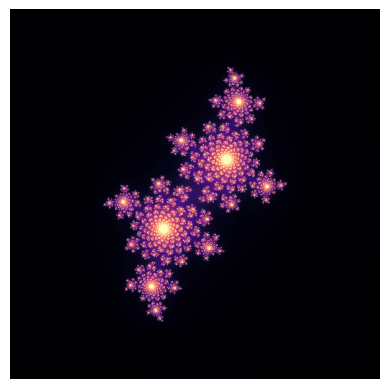

In [11]:
width, height = 1000, 1000
max_iters = 150
img = np.zeros((width, height))
def generate_julia_set(c):
    for x in range(width):
        for y in range(height):
            n = 0 # number of iterations
            i = -2.0 + x / width * 4.0
            j = -2.0 + y / height * 4.0
            z = complex(i,j)
            while abs(z) <= 2 and n < max_iters: 
                # while the point remains bounded
                z = z*z + c
                n+=1
            img[x,y] = n
    plt.imshow(img, cmap="magma", extent=(-2.0, 2.0, -2.0, 2.0))
    plt.axis("off")
    plt.savefig("julia_set.png")

generate_julia_set(-0.4 + 0.6j)

## Box-counting Dimension
There exist multiple methods to measure a geometrical object's non-integer dimension. The Hausdorff dimension, for instance, is defined through the Hausdorff measure. Several other definitions exist, such as the box-counting dimension or the self-similarity dimension.
The box-counting dimension, also referred to as the Minkowski-Bouligand dimension, is calculated based on the number of boxes $N(\epsilon)$ of side length $\epsilon$ required to cover a geometrical object. In the Minkowski formulation, $N(\epsilon)$ represents the number of balls of diameter $\epsilon$ needed to cover a set.

The dimension can be computed from the following formula:
$$ D = \lim_{\epsilon \to 0} \frac{\log(N(\epsilon))}{\log(1/\epsilon)} = \lim_{\epsilon \to 0} -\frac{\log(N(\epsilon))}{\log(\epsilon)} $$

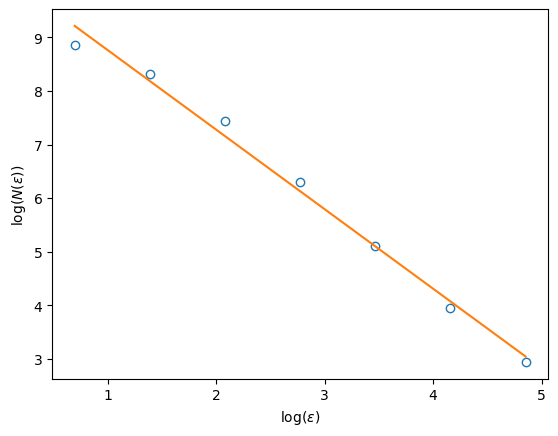

The box-counting dimension is approximately 1.483


In [ ]:
# adapted from francesco turci on wordpress
def box_counting(z):

    n = 2**int(np.ceil(np.log2(max(z.shape))))
    
    # defining sizes (lengths of sides) to evaluate
    sizes = 2 ** np.arange(1, int(np.log2(n)) -2)

    # storing N(epsilon) per length
    counts = []

    # pixel coordinates
    i, j = np.nonzero(z)

    for size in sizes:
        counts.append(len(np.unique(np.column_stack((i//size, j//size)), axis=0)))

    coeffs = np.polyfit(np.log(sizes), np.log(counts), 1)
    # D is the negative of the slope of the linear fit of log(N) against log(epsilon)
    D = -coeffs[0]

    plt.plot(np.log(sizes), np.log(counts), 'o', mfc="none")
    plt.plot(np.log(sizes), np.polyval(coeffs, np.log(sizes)))
    plt.xlabel(r"$\log(\epsilon)$")
    plt.ylabel(r"$\log(N(\epsilon))$")
    plt.show()

    print(f"The box-counting dimension is approximately {D:.3f}")

z = img >= max_iters

box_counting(z)